In [1]:
import pickle
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import collections
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

In [2]:
DATA_PATH = r"D:\python\ASL\idea\RealTime-ASL-Translator\VSL.pickle" 
MODEL_SAVE_PATH = r"D:\python\ASL\idea\RealTime-ASL-Translator\best_model.p"
NOISE_LEVEL_TRAIN = 0.02  # Thêm 2% nhiễu vào Train
CV_FOLDS = 5              # K-Fold = 5

models_config = {
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=15, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42, max_depth=15),
    "SVM (Linear)": SVC(kernel='linear', random_state=42)
}

In [3]:
def augment_data(X_data, y_data):
    """
    Tăng cường dữ liệu cho tập TRAIN:
    - Giúp model học được các góc nghiêng nhẹ (+/- 15 độ)
    - Giúp model không bị học thuộc lòng tọa độ cứng.
    """
    print("   -> Đang Augment dữ liệu (Xoay & Lật)...")
    augmented_X, augmented_y = [], []
    for features, label in zip(X_data, y_data):
        augmented_X.append(features)
        augmented_y.append(label)
        
        # Reshape để xoay
        landmarks = features.reshape(-1, 2)
        center = np.mean(landmarks, axis=0)
        centered = landmarks - center 
        
        # Chỉ xoay nhẹ +/- 15 độ (vừa đủ để model linh hoạt)
        for angle in [-15, 15]:
            rad = np.radians(angle)
            rot_x = centered[:, 0] * np.cos(rad) - centered[:, 1] * np.sin(rad)
            rot_y = centered[:, 0] * np.sin(rad) + centered[:, 1] * np.cos(rad)
            rotated = np.column_stack([rot_x, rot_y]) + center
            augmented_X.append(rotated.flatten())
            augmented_y.append(label)
            
    return np.array(augmented_X), np.array(augmented_y)

def add_noise(X_data, level):
    """Thêm nhiễu Gaussian vào tập TRAIN"""
    print(f"   -> Đang thêm nhiễu ngẫu nhiên (Level={level})...")
    noise = np.random.normal(0, level, X_data.shape)
    return X_data + noise

In [4]:
print("--- BẮT ĐẦU XỬ LÝ DỮ LIỆU ---")
# Load Data
try:
    with open(DATA_PATH, "rb") as f:
        data_dict = pickle.load(f)
except FileNotFoundError:
    print(f"Lỗi: Không tìm thấy file {DATA_PATH}")
    exit()

# Lọc dữ liệu (chỉ lấy 42 features)
data, labels = [], []
for f, l in zip(data_dict["dataset"], data_dict["labels"]):
    if len(f) == 42: data.append(f); labels.append(l)
    elif len(f) == 84: data.append(f[:42]); labels.append(l)

data = np.array(data)
labels = np.array(labels)

# Lọc bỏ nhãn ít mẫu (<5)
filtered_data, filtered_labels = [], []
counter = collections.Counter(labels)
for d, l in zip(data, labels):
    if counter[l] >= 5:
        filtered_data.append(d)
        filtered_labels.append(l)
data = np.array(filtered_data)
labels = np.array(filtered_labels)

# --- QUAN TRỌNG: CHIA TRAIN/TEST NGẪU NHIÊN (SHUFFLE=TRUE) ---
X_train, X_test, y_train, y_test = train_test_split(
    data, labels, 
    test_size=0.2, 
    shuffle=True,      # Trộn đều -> Kết quả Test sẽ cao
    stratify=labels,   # Đảm bảo đủ các nhãn
    random_state=42
)

print(f"Kích thước tập Train gốc: {len(X_train)}")
print(f"Kích thước tập Test gốc:  {len(X_test)}")

# 1. Augment (Xoay)
X_train_aug, y_train_aug = augment_data(X_train, y_train)
# 2. Add Noise (Nhiễu)
X_train_ready = add_noise(X_train_aug, level=NOISE_LEVEL_TRAIN)

print(f"Kích thước tập Train sau khi xử lý: {len(X_train_ready)}")

--- BẮT ĐẦU XỬ LÝ DỮ LIỆU ---
Kích thước tập Train gốc: 32240
Kích thước tập Test gốc:  8060
   -> Đang Augment dữ liệu (Xoay & Lật)...
   -> Đang thêm nhiễu ngẫu nhiên (Level=0.02)...
Kích thước tập Train sau khi xử lý: 96720


In [5]:
results_summary = []
best_model_name = ""
best_acc = 0.0
best_model_obj = None
best_y_pred = []

print("\n" + "="*60)
print(f"BẮT ĐẦU HUẤN LUYỆN & K-FOLD ({CV_FOLDS} Folds)")
print("="*60)

for name, model in models_config.items():
    print(f">> Đang chạy: {name}...", end=" ")
    
    # 1. K-FOLD CROSS VALIDATION (Trên tập Train đã xử lý)
    # Để chứng minh độ ổn định
    skf = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=42)
    cv_scores = cross_val_score(model, X_train_ready, y_train_aug, cv=skf, scoring='accuracy')
    cv_mean = cv_scores.mean()
    
    # 2. TRAIN & TEST (Test trên tập sạch)
    model.fit(X_train_ready, y_train_aug)
    y_pred = model.predict(X_test)     # Test sạch
    test_acc = accuracy_score(y_test, y_pred)
    
    print(f"-> Xong! (CV: {cv_mean*100:.2f}% | Test: {test_acc*100:.2f}%)")
    
    results_summary.append({
        "Model": name,
        "Độ ổn định (CV Score)": f"{cv_mean*100:.2f}%",
        "Độ chính xác (Test Acc)": f"{test_acc*100:.2f}%"
    })
    
    # Lưu model tốt nhất theo Test Acc
    if test_acc > best_acc:
        best_acc = test_acc
        best_model_name = name
        best_model_obj = model
        best_y_pred = y_pred


BẮT ĐẦU HUẤN LUYỆN & K-FOLD (5 Folds)
>> Đang chạy: Random Forest... -> Xong! (CV: 98.84% | Test: 99.39%)
>> Đang chạy: Decision Tree... -> Xong! (CV: 95.65% | Test: 99.31%)
>> Đang chạy: SVM (Linear)... -> Xong! (CV: 98.15% | Test: 98.98%)



🏆 BẢNG TỔNG HỢP KẾT QUẢ
        Model Độ ổn định (CV Score) Độ chính xác (Test Acc)
Random Forest                98.84%                  99.39%
Decision Tree                95.65%                  99.31%
 SVM (Linear)                98.15%                  98.98%

--------------------------------------------------------------------------------
✅ MODEL TỐT NHẤT: RANDOM FOREST
   Với độ chính xác kiểm thử: 99.39%
--------------------------------------------------------------------------------


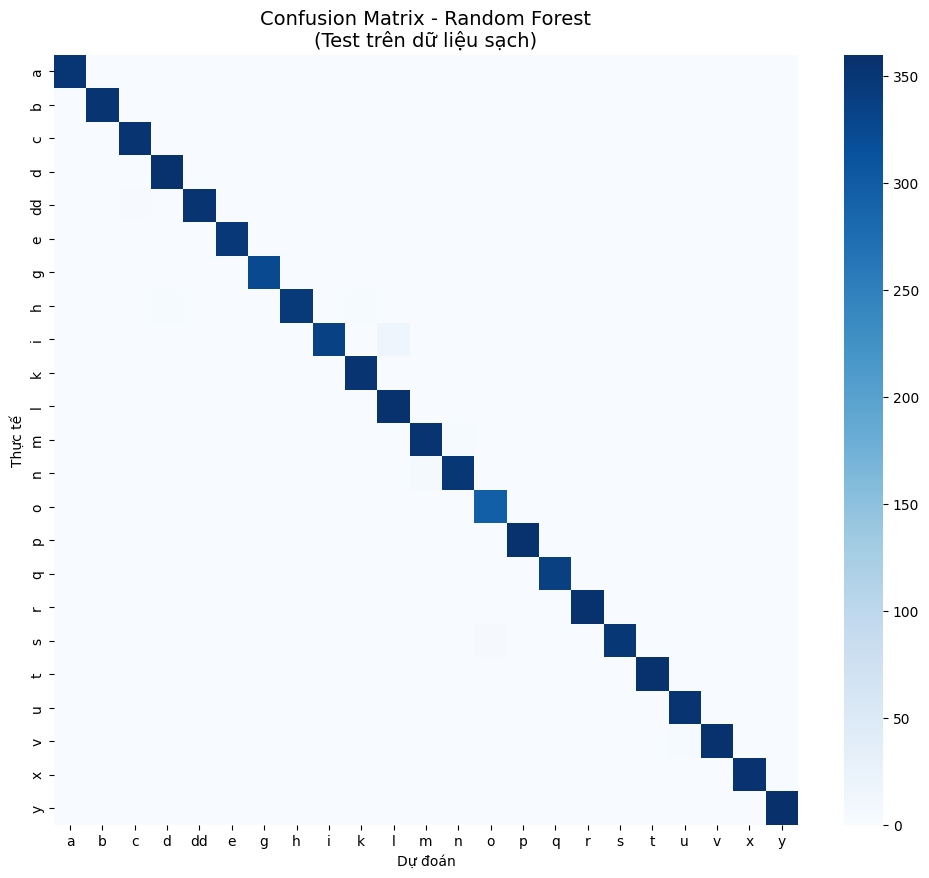


💾 Đã lưu model 'Random Forest' vào: D:\python\ASL\idea\RealTime-ASL-Translator\best_model.p


In [6]:
print("\n" + "="*60)
print("🏆 BẢNG TỔNG HỢP KẾT QUẢ")
print("="*60)
df_results = pd.DataFrame(results_summary)
df_results = df_results.sort_values(by="Độ chính xác (Test Acc)", ascending=False)
print(df_results.to_string(index=False))

print("\n" + "-"*80)
print(f"✅ MODEL TỐT NHẤT: {best_model_name.upper()}")
print(f"   Với độ chính xác kiểm thử: {best_acc*100:.2f}%")
print("-"*80)

# Vẽ Confusion Matrix cho Model tốt nhất
plt.figure(figsize=(12, 10))
cm = confusion_matrix(y_test, best_y_pred)
labels_sorted = sorted(np.unique(y_test))
sns.heatmap(cm, annot=False, fmt='d', cmap='Blues', 
            xticklabels=labels_sorted, yticklabels=labels_sorted)
plt.title(f"Confusion Matrix - {best_model_name}\n(Test trên dữ liệu sạch)", fontsize=14)
plt.xlabel("Dự đoán")
plt.ylabel("Thực tế")
plt.show()

# Lưu model
if best_model_obj:
    with open(MODEL_SAVE_PATH, 'wb') as f:
        pickle.dump({'model': best_model_obj}, f)
    print(f"\n💾 Đã lưu model '{best_model_name}' vào: {MODEL_SAVE_PATH}")